# 07 · Project 2 starts here: node features for the graph neural networks

Notebook 06 ended with the plan: test whether the honest networks actually improve predictions. Before any model can be trained, every stay (one dot in the network) needs **numbers describing it**. This notebook decides what those numbers are, for both questions, and checks which of them carry signal.

Peeking can sneak in two ways: through *which stays are linked* (the network) and through *what each stay is described by* (the features). So we build every combination:

| | features: honest | features: cheating |
|---|---|---|
| **network: honest** | the one you could really use | cheating features only |
| **network: cheating** | cheating links only | everything cheats |
| **network: random** | control: real features, meaningless links | |

Nothing here is computed from the outcomes. **No train/test split is made yet**; each stay's patient is kept so one can be added later without splitting a patient across sets.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
# import sys
# import os

from ehrgraph.eval.aggregate import write_aggregate
from ehrgraph.gnn.node_features import (
    FEATURE_SETS, LEAKABLE_BLOCKS, ablation_rows, block_ablation, build_pyg_data, check_data,
    code_gap_table, column_auroc, make_blocks, top_codes,
)
from ehrgraph.netstats.task_analysis import PRIMARY_VARIANT, analyze_task, task_graphs_from_labels
from ehrgraph.project import setup
from ehrgraph.viz import network_figures as nf

p = setup()  # finds the data in data/omop/

nf.apply_style()
TASKS = {"guo_los": "long stay", "new_hypertension": "new high blood pressure"}
NAME = {"safe": "honest", "leaky": "cheating", "null": "random"}   # the report's words
CLMBR_PATH = None   # full release only: Path(ASSETS) / "features" / "clmbr_features.pkl"
                    # with None the CLMBR parts are simply skipped

data folder: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/data/omop
results go to: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/results/aggregate


## Rebuild the networks

Notebooks 02 and 03 only save summary numbers (no patient data), so the networks are rebuilt here. We keep one random network per question (`n_null=1`), which is all this notebook needs. This takes a few minutes per question.

In [2]:
nets, results, y, groups = {}, {}, {}, {}
for task in TASKS:
    # nets[task] = task_graphs_from_labels(p.diagnoses, p.labels(task), task)
    nets[task] = task_graphs_from_labels(p.diagnoses, p.labels(task), task,
                                         clmbr_path=CLMBR_PATH, n_null=1)
    results[task] = analyze_task(nets[task])      # supplies centralities and groups
    tg = nets[task]
    y[task] = np.array([tg.labels[n] for n in tg.nodes])
    groups[task] = pd.factorize(pd.Series([n[0] for n in tg.nodes]))[0]    # one id per patient
    print(f"{TASKS[task]}: {len(tg.nodes):,} stays, {tg.prevalence:.1%} with the outcome, "
          f"CLMBR on {len(tg.feature_nodes):,} stays")

long stay: 6,998 stays, 25.4% with the outcome, CLMBR on 0 stays
new high blood pressure: 3,511 stays, 12.8% with the outcome, CLMBR on 0 stays


In [ ]:
from pathlib import Path
from ehrgraph.gnn.stay_features import make_stay_blocks

# ---- EDIT THESE LINES to match your data folder ---------------------------------------------------
OMOP = Path("ADD OWN PATH")
PERSON_CSV, VISIT_CSV, MEAS_CSV = "person.csv", "visit_occurrence.csv", "measurement.csv"
LAB_CONCEPTS = {}           # {"creatinine": <concept_id>, "sodium": <concept_id>, ...}; empty = skip the lab blocks
# ---------------------------------------------------------------------------------------------------------

def pick(df, *names, required=True):
    # the first of `names` that is a column of df; if none is, say which columns the table has
    for n in names:
        if n in df.columns:
            return df[n]
    if required:
        raise KeyError(f"none of {names} is a column; this table has: {list(df.columns)}")
    return None

# person: patient_id, birth (datetime), sex ("F" / "M" / other)
pr = pd.read_csv(OMOP / PERSON_CSV)
pr.columns = pr.columns.str.lower()
print("person columns:", list(pr.columns))
birth = pd.to_datetime(pr["birth_datetime"], errors="coerce") if "birth_datetime" in pr.columns else pd.Series(pd.NaT, index=pr.index)
if "year_of_birth" in pr.columns:                    # fall back to year / month / day of birth where birth_datetime is empty
    ymd = pd.DataFrame({"year": pr["year_of_birth"],
                        "month": pr["month_of_birth"].fillna(7) if "month_of_birth" in pr.columns else 7,
                        "day": pr["day_of_birth"].fillna(1) if "day_of_birth" in pr.columns else 1})
    birth = birth.fillna(pd.to_datetime(ymd, errors="coerce"))
assert birth.notna().any(), "no birth information found: need birth_datetime or year_of_birth"
sex = pick(pr, "gender_source_value", required=False)
if sex is None:
    sex = pick(pr, "gender_concept_id").map({8532: "F", 8507: "M"})
person = pd.DataFrame({"patient_id": pick(pr, "person_id", "patient_id"), "birth": birth, "sex": sex})
print(f"birth known for {birth.notna().mean():.1%} of people; sex values: {person['sex'].value_counts(dropna=False).head(4).to_dict()}")

# visits: patient_id, start (datetime), kind ("inpatient" | "ed" | other)
vo = pd.read_csv(OMOP / VISIT_CSV)
vo.columns = vo.columns.str.lower()
print("visit columns:", list(vo.columns))
kind = pick(vo, "visit_concept_id").map({9201: "inpatient", 262: "ed", 9203: "ed"}).fillna("other")
visits = pd.DataFrame({"patient_id": pick(vo, "person_id", "patient_id"),
                       "start": pd.to_datetime(pick(vo, "visit_start_datetime", "visit_start_date"), errors="coerce"), "kind": kind})
print("visit kinds:", kind.value_counts().to_dict())          # mostly 'other'? then the concept ids above do not match your data

# labs (optional): patient_id, time, name, value
labs = None
if LAB_CONCEPTS:
    ms = pd.read_csv(OMOP / MEAS_CSV)
    ms.columns = ms.columns.str.lower()
    print("measurement columns:", list(ms.columns))
    inv = {v: k for k, v in LAB_CONCEPTS.items()}
    labs = pd.DataFrame({"patient_id": pick(ms, "person_id", "patient_id"),
                         "time": pd.to_datetime(pick(ms, "measurement_datetime", "measurement_date"), errors="coerce"),
                         "name": pick(ms, "measurement_concept_id").map(inv),
                         "value": pick(ms, "value_as_number")}).dropna(subset=["name", "value", "time"])
    assert len(labs) > 0, "no lab rows matched LAB_CONCEPTS"
    print("lab rows per test:", labs["name"].value_counts().to_dict())

# the patient ids in the tables must be the ones the stays use
for t in TASKS:
    ids = {str(n[0]) for n in nets[t].nodes}
    share = len(ids & set(person["patient_id"].astype(str))) / len(ids)
    print(f"{TASKS[t]}: {share:.1%} of patients found in the person table")
    assert share > 0.99, "patient ids do not match between the stays and the person table"

extra = {t: make_stay_blocks(nets[t].nodes, person, visits, labs, list(LAB_CONCEPTS)) for t in TASKS}
print({t: {k: v.values.shape[1] for k, v in extra[t].items()} for t in TASKS})

person columns: ['person_id', 'gender_concept_id', 'year_of_birth', 'month_of_birth', 'day_of_birth', 'birth_datetime', 'race_concept_id', 'ethnicity_concept_id', 'location_id', 'provider_id', 'care_site_id', 'person_source_value', 'gender_source_value', 'gender_source_concept_id', 'race_source_value', 'race_source_concept_id', 'ethnicity_source_value', 'ethnicity_source_concept_id', 'trace_id', 'unit_id', 'load_table_id']
birth known for 100.0% of people; sex values: {'2 |': 2842, '1 |': 1952, '1 | 1': 1484, '2 | 2': 453}
visit columns: ['visit_occurrence_id', 'person_id', 'visit_concept_id', 'visit_start_date', 'visit_start_datetime', 'visit_end_date', 'visit_end_datetime', 'visit_type_concept_id', 'provider_id', 'care_site_id', 'visit_source_value', 'visit_source_concept_id', 'admitting_source_concept_id', 'admitting_source_value', 'discharge_to_concept_id', 'discharge_to_source_value', 'preceding_visit_occurrence_id', 'trace_id', 'unit_id', 'load_table_id']
visit kinds: {'other': 8

In [10]:
# Sanity check on the new blocks before anything is trained on them.
for t in TASKS:
    e = extra[t]
    print(TASKS[t])
    print(f"  current visit found for {e['admission'].values[:, 3].mean():.0%} of stays "
          f"(inpatient {e['admission'].values[:, 0].mean():.0%}, ED {e['admission'].values[:, 1].mean():.0%})")
    print(f"  age {e['demo'].values[:, 0].min():.0f} to {e['demo'].values[:, 0].max():.0f}, "
          f"missing {e['demo'].values[:, 3].mean():.0%}")
    print(f"  prior inpatient admissions in the past year: mean {np.expm1(e['prior_use'].values[:, 0]).mean():.2f}")
    if "labs" in e:
        print("  lab missing share:", {c: f"{e['labs'].values[:, i].mean():.0%}"
                                       for i, c in enumerate(e['labs'].columns) if c.endswith("_missing")})
    else:
        print("  no lab blocks (LAB_CONCEPTS is empty)")

long stay
  current visit found for 100% of stays (inpatient 95%, ED 0%)
  age 19 to 89, missing 0%
  prior inpatient admissions in the past year: mean 4.15
  no lab blocks (LAB_CONCEPTS is empty)
new high blood pressure
  current visit found for 27% of stays (inpatient 7%, ED 0%)
  age 19 to 89, missing 0%
  prior inpatient admissions in the past year: mean 4.46
  no lab blocks (LAB_CONCEPTS is empty)


## What describes a stay?

Each description is a named block of numbers:

| block | what it is | needs the network? | can cheat? |
|---|---|---|---|
| `dx_svd` | the stay's diagnoses, rare ones weighted up, squeezed into 64 numbers | no | yes, if fed the whole record |
| `dx_summary` | how many different diagnoses the stay has (cheating stays have about twice as many) | no | yes |
| `structure` | how many links, how many closed triangles, how central, how many links to the same patient | yes | through the links |
| `rwpe` | how likely a short random walk is to come back to the stay (a "role in the neighbourhood" number) | yes | through the links |
| `n2v` | **node2vec**: random walks around the network, then 64 numbers learned so that stays that appear near each other get similar numbers | yes | through the links |
| `clmbr` | Stanford's pretrained patient summary at the prediction time | no | should not (to verify) |
| `time` | prediction year (only used as a check, because of the 2015 code switch) | no | no |
| `demo` | age at the prediction time and sex | no | no |
| `admission` | what kind of encounter the stay is (inpatient, ED), hour and weekday of the prediction time | no | no |
| `prior_use` | admissions and ED visits in the past year, days since the last admission | no | no |
| `comorbidity` | Charlson score and one flag per condition, computed from the stay's diagnoses | no | yes, like `dx_svd` |
| `labs` | latest value of each chosen lab before the prediction time, plus a missing flag | no | no |

`demo`, `admission`, `prior_use` and `labs` use only events at or before the prediction time, so they are the same under every condition (like CLMBR). `comorbidity` is built from the diagnosis vectors, so it follows the honest / cheating choice.

node2vec uses 10 walks of length 30 per stay, a context window of 5, 5 noise samples per pair, and unbiased walks (`p = q = 1`). Those two knobs can be swept later.

In [11]:
GRID = [("safe", "safe"), ("safe", "leaky"), ("leaky", "safe"), ("leaky", "leaky"), ("null", "safe")]
N2V = dict(dim=64, num_walks=10, walk_length=30, window=1, negatives=5, epochs=5, p=4.0, q=0.25)

blocks, n2v_cache = {}, {}
for task, tg in nets.items():
    n2v_cache[task] = {}      # node2vec depends on the network only: train once per network
    blocks[task] = {
        (g, s): make_blocks(tg, g, s, centrality=results[task].centrality[g], svd_dim=64,
                    rw_steps=8, n2v=N2V, n2v_cache=n2v_cache[task],
                    extra_blocks=extra[task])
        for g, s in GRID
    }

for task in TASKS:
    print(TASKS[task], {k: v.values.shape[1] for k, v in blocks[task][("safe", "safe")].items()})
    print("   stays with no links (node2vec can't walk from them, they get zeros):",
          {NAME[g]: f"{b.meta['isolated']:,}" for g, b in n2v_cache[task].items()})

long stay {'dx_svd': 64, 'dx_summary': 1, 'time': 1, 'structure': 7, 'rwpe': 8, 'n2v': 65, 'comorbidity': 18, 'demo': 4, 'admission': 8, 'prior_use': 3}
   stays with no links (node2vec can't walk from them, they get zeros): {'honest': '301', 'cheating': '539', 'random': '301'}
new high blood pressure {'dx_svd': 64, 'dx_summary': 1, 'time': 1, 'structure': 7, 'rwpe': 8, 'n2v': 65, 'comorbidity': 18, 'demo': 4, 'admission': 8, 'prior_use': 3}
   stays with no links (node2vec can't walk from them, they get zeros): {'honest': '172', 'cheating': '262', 'random': '172'}


In [12]:
# what an honest "diagnosis axis" means, in real diagnoses (first three axes, long stay)
task = "guo_los"
for c in range(3):
    tc = top_codes(blocks[task][("safe", "safe")]["dx_svd"], c, n=8)
    print(f"axis {c}"); display(tc.assign(diagnosis=tc.code.map(p.names(tc.code)))[["diagnosis", "loading"]])

axis 0


,diagnosis,loading
0,Essential hypertension,0.171166
1,Hyperlipidemia,0.154760
2,Electrocardiogram abnormal,0.139112
3,Type 2 diabetes mellitus without complication,0.118993
4,Anemia,0.112815
5,Lung field abnormal,0.107729
6,Dyspnea,0.107696
7,Pleural effusion,0.105698


axis 1


,diagnosis,loading
0,Single live birth,0.343018
1,Finding related to pregnancy,0.323212
2,Third trimester pregnancy,0.250134
3,Unplanned pregnancy,0.211807
4,Disorder of pregnancy,0.192140
5,"Gestation period, 39 weeks",0.188106
6,High risk pregnancy,0.179713
7,Maternal AND/OR fetal condition affecting labo...,0.176932


axis 2


,diagnosis,loading
0,Congestive heart failure,0.199631
1,Hyperlipidemia,0.179137
2,Atrial fibrillation,0.146604
3,Essential hypertension,0.134753
4,Fever,-0.129350
5,Atherosclerosis of coronary artery without ang...,0.123498
6,Coronary atherosclerosis,0.123291
7,Coronary arteriosclerosis,0.122142


### Does node2vec reflect the network?

Cosine similarity (1 = same direction) between node2vec numbers for two stays in the **same Leiden group** vs. two random stays. Honest and cheating networks should show a clear gap. The random network, which has no group structure, should show almost none. The numbers are only comparable *within* one network, so read each row on its own.

In [13]:
rng = np.random.default_rng(0)
rows = []
for task, tg in nets.items():
    for g in ("safe", "leaky", "null"):
        b = n2v_cache[task][g].values
        z, ok = b[:, :-1], b[:, -1] == 0
        part = results[task].communities[g]["leiden"].to_dict()
        comm = np.array([part.get(n, -1) for n in tg.nodes])
        zn = z / np.clip(np.linalg.norm(z, axis=1, keepdims=True), 1e-9, None)
        idx = np.flatnonzero(ok & (comm >= 0))
        a, c = rng.choice(idx, 20000), rng.choice(idx, 20000)
        same = (comm[a] == comm[c]) & (a != c)
        cos = (zn[a] * zn[c]).sum(1)
        rows.append({"question": TASKS[task], "network": NAME[g],
                     "same group": cos[same].mean(), "different groups": cos[~same].mean()})
pd.DataFrame(rows).set_index(["question", "network"]).round(2)

same group  different groups
question                network                               
long stay               honest          0.47              0.36
                        cheating        0.49              0.37
                        random          0.33              0.32
new high blood pressure honest          0.50              0.36
                        cheating        0.52              0.37
                        random          0.33              0.32

## CLMBR next to the networks

CLMBR is our honest reference, so first: how does it relate to each network? `dirichlet_energy_clmbr` (from the analysis in notebooks 02 and 03) measures how different CLMBR's numbers are across a network's links. **Lower means linked stays look more alike to CLMBR.** If the honest network sits well below the random one, our diagnosis network and CLMBR agree on what a "similar patient" is.

In [14]:
if CLMBR_PATH is None:
    print("No CLMBR in this run (CLMBR_PATH is None).")
else:
    clmbr = pd.concat({
        TASKS[t]: pd.DataFrame([r for r in results[t].rows
                                if r["metric"] in ("dirichlet_energy_clmbr", "clmbr_coverage")])
        .pivot_table(index="metric", columns="condition", values="value")
        for t in TASKS
    })
    display(clmbr.round(3))

No CLMBR in this run (CLMBR_PATH is None).


## Which features matter?

Three views, finest to coarsest. They are **descriptive** (they use all outcomes, like the homophily numbers in notebooks 02 and 03) and involve no neural network.

1. **Diagnoses:** how often do positive vs. negative stays have each diagnosis? This is where a leak shows up *by name*.
2. **Single numbers:** how well does each network-based number alone separate the outcome? (0.5 = not at all.)
3. **Blocks:** a simple tree model on each block alone, and on everything *except* that block. The score is always measured on patients the model hasn't seen (a patient's other stays never sit in the test fold), so a patient can't be recognised from their own other stay.

One cheating diagnosis can get watered down inside 64 mixed numbers, so view 1 is the direct detector and view 3 shows what survives.

In [15]:
for task, tg in nets.items():
    for s in ("safe", "leaky"):
        matrix, codes = tg.vectors[s]
        gap = code_gap_table(matrix, codes, y[task], top=8)
        print(f"--- {TASKS[task]}: biggest differences, {NAME[s]} diagnoses")
        display(gap.assign(diagnosis=gap.code.map(p.names(gap.code)))
                [["diagnosis", "positive_rate", "negative_rate", "gap"]].round(2))

--- long stay: biggest differences, honest diagnoses


,diagnosis,positive_rate,negative_rate,gap
0,Acute renal failure syndrome,0.33,0.15,0.19
1,Pleural effusion,0.33,0.17,0.16
2,Acute posthemorrhagic anemia,0.28,0.14,0.14
3,Atrial fibrillation,0.24,0.12,0.12
4,Acidosis,0.18,0.07,0.12
5,Hypervolemia,0.17,0.06,0.11
6,Thrombocytopenic disorder,0.22,0.10,0.11
7,Congestive heart failure,0.24,0.13,0.11


--- long stay: biggest differences, cheating diagnoses


,diagnosis,positive_rate,negative_rate,gap
0,Pleural effusion,0.63,0.37,0.27
1,Acute renal failure syndrome,0.50,0.28,0.21
2,Atelectasis,0.53,0.31,0.21
3,Sepsis,0.38,0.21,0.17
4,Cardiomegaly,0.43,0.27,0.17
5,Hypervolemia,0.30,0.13,0.17
6,Electrocardiogram abnormal,0.73,0.57,0.16
7,Ascites,0.32,0.16,0.16


--- new high blood pressure: biggest differences, honest diagnoses


,diagnosis,positive_rate,negative_rate,gap
0,Single live birth,0.03,0.14,-0.11
1,Finding related to pregnancy,0.04,0.15,-0.11
2,Hyperlipidemia,0.24,0.14,0.11
3,Hypo-osmolality and or hyponatremia,0.17,0.07,0.10
4,Cardiomegaly,0.19,0.09,0.10
5,Congestive heart failure,0.17,0.07,0.10
6,Electrocardiogram abnormal,0.33,0.24,0.09
7,Pleural effusion,0.25,0.15,0.09


--- new high blood pressure: biggest differences, cheating diagnoses


,diagnosis,positive_rate,negative_rate,gap
0,Essential hypertension,1.00,0.13,0.87
1,Hyperlipidemia,0.64,0.27,0.37
2,Pleural effusion,0.58,0.29,0.29
3,Acute renal failure syndrome,0.48,0.20,0.28
4,Cardiomegaly,0.42,0.15,0.27
5,Anemia,0.62,0.36,0.26
6,Electrocardiogram abnormal,0.69,0.43,0.26
7,Dyspnea,0.55,0.30,0.25


In [16]:
for task in TASKS:
    print(TASKS[task]); display(column_auroc(blocks[task][("safe", "safe")]["structure"], y[task]).round(3))

long stay


,column,auroc
0,eigenvector_pct,0.528
1,log_degree,0.472
2,n_same_patient_neighbors,0.522
3,core_number,0.482
4,clustering,0.492
5,closeness_pct,0.504
6,betweenness_pct,0.498


new high blood pressure


,column,auroc
0,closeness_pct,0.590
1,eigenvector_pct,0.575
2,n_same_patient_neighbors,0.430
3,betweenness_pct,0.534
4,clustering,0.470
5,log_degree,0.494
6,core_number,0.499


In [17]:
NAMES = ["dx_svd", "dx_summary", "comorbidity", "demo", "admission", "prior_use", "labs",
         "structure", "rwpe", "n2v", "time", "clmbr"]   # missing blocks are skipped. "ALL" = every block named here
ABLATE = [("safe", "safe")]      # honest network + honest features; use GRID for the full set (a few minutes per question)

ablation, alone = {}, {}
for task in TASKS:
    ablation[task] = {(g, s): block_ablation(blocks[task][(g, s)], NAMES, y[task], groups[task])
                      for g, s in ABLATE}
    alone[task] = pd.concat(
        {f"network: {NAME[g]} | features: {NAME[s]}": t.set_index("block")["alone_auroc"]
         for (g, s), t in ablation[task].items()}, axis=1)
    print(TASKS[task], "- how well each block alone predicts (0.5 = not at all)")
    display(alone[task].round(3))
    print("   how much the best score drops without that block")
    display(pd.concat({f"network: {NAME[g]} | features: {NAME[s]}":
                       t.set_index("block")["auroc_lost_when_dropped"]
                       for (g, s), t in ablation[task].items()}, axis=1).round(3))

long stay - how well each block alone predicts (0.5 = not at all)


,network: honest | features: honest
block,
ALL,0.777
dx_svd,0.773
dx_summary,0.572
comorbidity,0.500
demo,0.541
admission,0.498
prior_use,0.518
structure,0.581
rwpe,0.535


   how much the best score drops without that block


,network: honest | features: honest
block,
ALL,NaN
dx_svd,0.081
dx_summary,0.004
comorbidity,0.000
demo,-0.002
admission,0.001
prior_use,-0.002
structure,-0.003
rwpe,0.000


new high blood pressure - how well each block alone predicts (0.5 = not at all)


,network: honest | features: honest
block,
ALL,0.685
dx_svd,0.660
dx_summary,0.554
comorbidity,0.499
demo,0.568
admission,0.484
prior_use,0.545
structure,0.587
rwpe,0.519


   how much the best score drops without that block


,network: honest | features: honest
block,
ALL,NaN
dx_svd,0.029
dx_summary,-0.000
comorbidity,0.000
demo,0.005
admission,-0.004
prior_use,0.006
structure,0.011
rwpe,-0.010


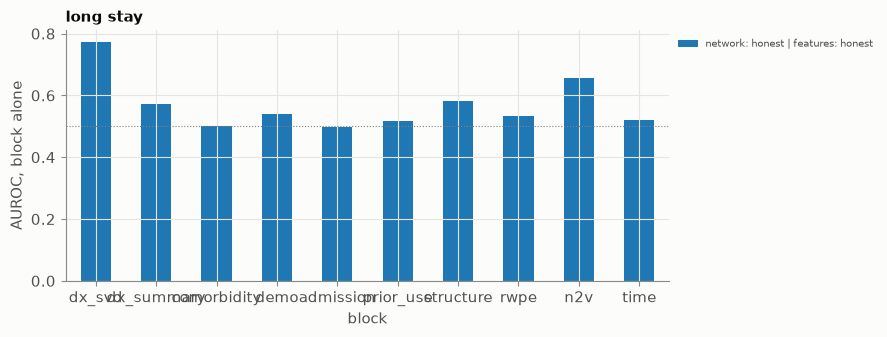

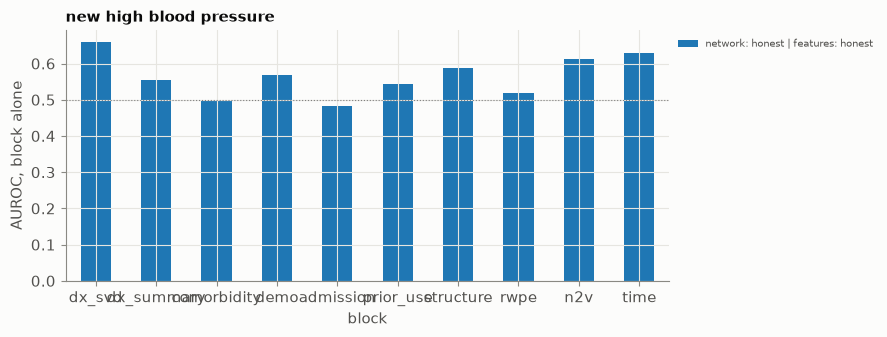

In [18]:
for task in TASKS:
    ax = alone[task].drop(index="ALL").plot.bar(figsize=(9, 3.5), rot=0, title=TASKS[task])
    ax.axhline(0.5, color="grey", lw=0.8, ls=":"); ax.set_ylabel("AUROC, block alone")
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1)); plt.tight_layout()
    nf.save(ax.figure, p.figures / f"07_feature_blocks_{task}.png")
    plt.show()

### Which feature set predicts best?

The cell above scores each block; this one scores the **feature sets** the neural networks will be given. Same simple tree model, honest network and honest diagnoses, out-of-fold AUROC averaged over 3 splits. `time` is calendar year alone. If `dx_ctx` and `dx_ctx_labs` are not clearly above `dx` (on blood pressure, a gain under about 0.01 is inside the noise), the new features are unlikely to help the networks either. A new block that scores very high on its own on an honest run is a warning of leakage, so check its timing rule before trusting it.

In [19]:
# Which feature SET predicts best? One tree model per set on honest features, out-of-fold and grouped by patient,
# averaged over 3 split seeds. `time` (calendar year alone) is the reference line. No neural network involved.
from ehrgraph.gnn.node_features import _oof_auc

SETS = ["dx", "ctx", "dx_comorb", "dx_ctx", "ctx_labs", "dx_ctx_labs"]
rows = []
for t in TASKS:
    b = blocks[t][("safe", "safe")]
    for fs in SETS + ["time"]:
        names = FEATURE_SETS[fs] if fs != "time" else ["time"]
        if all(n in b for n in names):
            X = np.hstack([b[n].values for n in names])
            rows.append({"question": TASKS[t], "feature set": fs,
                         "AUROC": np.mean([_oof_auc(X, y[t], groups[t], s) for s in range(3)])})
display(pd.DataFrame(rows).pivot(index="feature set", columns="question", values="AUROC").round(3))

question,long stay,new high blood pressure
feature set,,
ctx,0.547,0.607
dx,0.773,0.651
dx_comorb,0.773,0.651
dx_ctx,0.775,0.664
time,0.524,0.626


## Build the inputs for the neural networks

One `Data` object per combination (network, features, feature set). Feature sets that don't use diagnoses (`structure`, `n2v`, `clmbr`, `clmbr_n2v`) ignore the feature version, so only the honest one is built for them. The numbers are **not yet scaled**: scaling must use only training stays, so it waits for the split (`standardize`).

The new clinical feature sets (`ctx`, `ctx_labs`, `dx_comorb`, `dx_ctx`, `dx_ctx_labs`) are built here too. They are saved to a **separate file** below so the existing inputs stay exactly as they were.

In [20]:
datasets = {}
for task, tg in nets.items():
    datasets[task] = {}
    for g, s in GRID:
        for fs, names in FEATURE_SETS.items():
            if not any(n in LEAKABLE_BLOCKS for n in names) and s == "leaky":
                continue                      # identical to the honest-features version
            if not all(n in blocks[task][(g, s)] for n in names):
                continue                      # e.g. clmbr without the full release
            datasets[task][(g, s, fs)] = build_pyg_data(tg, g, s, fs, blocks=blocks[task][(g, s)])
    for d in datasets[task].values():
        check_data(d)

summary = pd.DataFrame([
    {"question": TASKS[t], "network": NAME[g], "features": NAME[s], "feature set": fs,
     "numbers per stay": d.x.shape[1], "links": d.edge_index.shape[1] // 2,
     "links within one patient": float(d.edge_attr.mean())}
    for t, ds in datasets.items() for (g, s, fs), d in ds.items()
])
display(summary.round(3))

/home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,question,network,features,feature set,numbers per stay,links,links within one patient
0,long stay,honest,honest,dx,65,18581,0.378
1,long stay,honest,honest,structure,15,18581,0.378
2,long stay,honest,honest,n2v,65,18581,0.378
3,long stay,honest,honest,dx_n2v,130,18581,0.378
4,long stay,honest,honest,ctx,15,18581,0.378
5,long stay,honest,honest,dx_comorb,83,18581,0.378
6,long stay,honest,honest,dx_ctx,98,18581,0.378
7,long stay,honest,cheating,dx,65,18581,0.378
8,long stay,honest,cheating,dx_n2v,130,18581,0.378
9,long stay,honest,cheating,dx_comorb,83,18581,0.378


In [21]:
# Optional: what if same-patient links are removed? (they carry about half the blood-pressure homophily)
# Note: node2vec was trained WITH those links; a fully clean version would retrain it on a network without them.
no_same = {t: build_pyg_data(nets[t], "safe", "safe", "dx_n2v", blocks=blocks[t][("safe", "safe")],
                             drop_same_patient_edges=True) for t in TASKS}
for t, d in no_same.items():
    print(TASKS[t], f"- {d.edge_index.shape[1] // 2:,} links without same-patient ones")

long stay - 11,562 links without same-patient ones
new high blood pressure - 6,905 links without same-patient ones


In [22]:
from ehrgraph.gnn.node_features import node2vec_block, block_ablation
task = "new_hypertension"; tg = nets[task]
auc = lambda b: block_ablation({"n2v": b}, ["n2v"], y[task], groups[task]).set_index("block").loc["n2v", "alone_auroc"]

for seed in range(3):
    print(seed, round(auc(node2vec_block(tg.graphs["safe"], tg.nodes, **{**N2V, "seed": seed})), 3))

g = tg.graphs["safe"].copy()
g.remove_edges_from([(u, v) for u, v in g.edges() if u[0] == v[0]])
print(round(auc(node2vec_block(g, tg.nodes, **N2V)), 3))

year = pd.Series([pd.Timestamp(n[1]).year for n in tg.nodes])
print(pd.Series(y[task]).groupby(year.values).agg(["mean", "size"]).round(2))

0 0.612
1 0.593
2 0.623
0.576
      mean  size
2007  0.50     6
2008  0.20   323
2009  0.25   346
2010  0.17   192
2011  0.18   234
2012  0.12   203
2013  0.15   172
2014  0.13   238
2015  0.06   289
2016  0.06   227
2017  0.08   241
2018  0.10   234
2019  0.12   193
2020  0.10   207
2021  0.09   225
2022  0.05   164
2023  0.00    17


## Save

These files hold patient-level data (stays are numbered, not named, but treat them as sensitive and keep them out of git). Loading needs `weights_only=False` because they contain PyG `Data` objects. The summary file holds only aggregate numbers, like the ones from notebooks 02 and 03.

In [23]:
NEW_SETS = {"ctx", "ctx_labs", "dx_comorb", "dx_ctx", "dx_ctx_labs"}
for task in TASKS:
    new = {k: d for k, d in datasets[task].items() if k[2] in NEW_SETS}
    torch.save(new, p.results / f"gnn_inputs_{task}_clinical.pt")
    print(task, sorted({k[2] for k in new}))
# later: datasets = torch.load(p.results / f"gnn_inputs_{task}.pt", weights_only=False)
#        datasets.update(torch.load(p.results / f"gnn_inputs_{task}_clinical.pt", weights_only=False))

agg = [r for t in TASKS for (g, s), tb in ablation[t].items()
       for r in ablation_rows(tb, t, g, s, PRIMARY_VARIANT)]
write_aggregate(agg, p.results / "node_feature_importance.csv")   # if this rejects the condition names, rename them in ablation_rows

guo_los ['ctx', 'dx_comorb', 'dx_ctx']
new_hypertension ['ctx', 'dx_comorb', 'dx_ctx']


PosixPath('/home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/results/aggregate/node_feature_importance.csv')

## What we learned



## Next
